# Thí nghiệm cấu hình A — Tinh chỉnh MLP

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [11]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (128, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.0011,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "random_state": 42,
    },
}

CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

## Đọc dữ liệu và chọn đặc trưng cấu hình A

In [12]:
from datetime import datetime
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

processed_dir = project_dir / "data" / "processed"
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=project_dir)
train, validation = data_splits["train"], data_splits["validation"]

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

for part in (train, validation):
    assert part[features_A + [TARGET_COLUMN]].notna().all().all()

X_train, y_train = train[features_A], train[TARGET_COLUMN]
X_validation, y_validation = validation[features_A], validation[TARGET_COLUMN]

## Huấn luyện MLP trên tập train

In [13]:
preprocessor = ColumnTransformer([
    (
        "calendar",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        CALENDAR_COLUMNS,
    ),
    ("binary", "passthrough", binary_columns),
])

# Chuẩn hóa mục tiêu từ train và đổi dự đoán về đơn vị xe/giờ.
model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", TransformedTargetRegressor(
        regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
        transformer=StandardScaler(),
    )),
])
model.fit(X_train, y_train);

## Đánh giá trên validation và lưu Excel

Sau mỗi lần đổi tham số, chạy lại cell Params, cell huấn luyện và cell đánh giá. Mỗi lần chạy cell đánh giá sẽ tạo một file Excel riêng trong thư mục thí nghiệm. Mỗi hàng ghi điểm validation và thông số của mô hình đã fit.

In [14]:
prediction_table = validation[["date_time", TARGET_COLUMN]].copy()
prediction = model.predict(X_validation)
if CLIP_NEGATIVE_PREDICTIONS:
    prediction = prediction.clip(min=0)
prediction_table["MLP"] = prediction

results = pd.DataFrame([{
    "Mô hình": "MLP",
    "MAE": mean_absolute_error(y_validation, prediction),
    "RMSE": mean_squared_error(y_validation, prediction) ** 0.5,
    "R2": r2_score(y_validation, prediction),
}])
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4}))

run_time = datetime.now().astimezone()
run_id = run_time.strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "17-11-2026_ConfigA_ModelLMP_Phuc"
excel_path = experiment_dir / f"ConfigA_MLP_{run_id}.xlsx"

fitted_mlp = model.named_steps["model"].regressor_
fitted_params = fitted_mlp.get_params()
run_details = {
    "run_id": run_id,
    "thời gian": run_time.isoformat(timespec="seconds"),
    "cấu hình": "A",
    "số mẫu train": len(y_train),
    "số mẫu validation": len(y_validation),
    "giới hạn dự đoán âm": CLIP_NEGATIVE_PREDICTIONS,
}
params_row = {name: fitted_params[name] for name in MODEL_PARAMS["MLP"]}
params_row["hidden_layer_sizes"] = str(params_row["hidden_layer_sizes"])
export = results.assign(**run_details, **params_row, n_iter=fitted_mlp.n_iter_)
export.to_excel(excel_path, sheet_name="Kết quả", index=False, engine="openpyxl")
print(f"Đã lưu Excel tại {excel_path}")

,Mô hình,MAE,RMSE,R2
0,MLP,255.974,377.495,0.9631


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\17-11-2026_ConfigA_ModelLMP_Phuc\ConfigA_MLP_20261117_231540_795214.xlsx


## Vẽ và lưu biểu đồ dự đoán

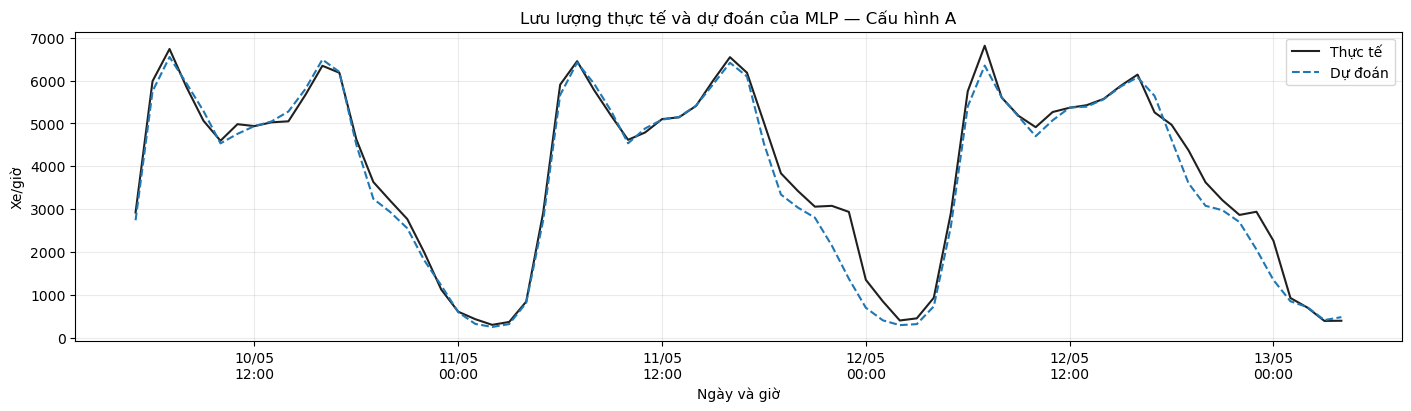

In [15]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
ax.plot(plot_data.index, plot_data["MLP"], linestyle="--", label="Dự đoán")
ax.set_title("Lưu lượng thực tế và dự đoán của MLP — Cấu hình A")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_a_mlp_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()